# Logistic Regression — Step-by-Step Practical (Scikit-learn Iris Dataset)

**Goal:** Classify a flower as **Versicolor (0)** or **Virginica (1)** using just two measurements.

**Why two features?** We can visualize the decision boundary and calculate the linear score and sigmoid probability ourselves.

**Learning path:** Dataset → Features/target → Train/test split → Standardization → Logistic Regression → Linear score $z$ → Sigmoid → Threshold → Evaluation → Decision boundary.

> **Important:** Logistic Regression **does not first fit a LinearRegression model**. It directly learns coefficients for a *linear score* $z=b_0+b_1x_1+b_2x_2$, then applies the sigmoid function to obtain a probability.

**Prerequisites:** `numpy`, `pandas`, `matplotlib`, `scikit-learn`. The Iris dataset comes with Scikit-learn; no download or CSV file is required.

## 1. Import the libraries

We use Pandas for tabular data, Matplotlib for graphs, and Scikit-learn to prepare, train, and evaluate the model.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score, confusion_matrix, ConfusionMatrixDisplay,
    classification_report, roc_auc_score, RocCurveDisplay, log_loss,
    precision_score, recall_score
)

pd.set_option("display.precision", 4)
print("Libraries imported successfully.")

Libraries imported successfully.


## 2. Load the standard Iris dataset

Scikit-learn's Iris dataset contains **150 flowers** from three species and four measurements. For our introductory **binary classification** example, we will select only *versicolor* and *virginica*.

In [ ]:
iris = load_iris(as_frame=True)
print("Original shape:", iris.frame.shape)
print("Original class names:", list(iris.target_names))
display(iris.frame.head())

Original shape: (150, 5)
Original class names: ['setosa', 'versicolor', 'virginica']


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target
0,5.1,3.5,1.4,0.2,0
1,4.9,3.0,1.4,0.2,0
2,4.7,3.2,1.3,0.2,0
3,4.6,3.1,1.5,0.2,0
4,5.0,3.6,1.4,0.2,0


## 3. Keep two classes and two features

- Original Iris target `1` is *versicolor* → our target **0**.
- Original Iris target `2` is *virginica* → our target **1**.
- `X` contains **petal length** and **petal width**.
- `y` contains the class that we want to predict.

We now have 100 observations (50 flowers per class), so 0 and 1 have clear meanings throughout the notebook.

In [ ]:
df = iris.frame[iris.frame["target"].isin([1, 2])].copy()

feature_names = ["petal length (cm)", "petal width (cm)"]
X = df[feature_names]
y = (df["target"] == 2).astype(int)  # versicolor=0, virginica=1

print("X shape:", X.shape)
print("y shape:", y.shape)
print("Class counts (0=versicolor, 1=virginica):")
print(y.value_counts().sort_index())
display(pd.concat([X.head(), y.head().rename("class_label")], axis=1))

X shape: (100, 2)
y shape: (100,)
Class counts (0=versicolor, 1=virginica):
target
0    50
1    50
Name: count, dtype: int64


,petal length (cm),petal width (cm),class_label
50,4.7,1.4,0
51,4.5,1.5,0
52,4.9,1.5,0
53,4.0,1.3,0
54,4.6,1.5,0


## 4. Visualize the observations

Each dot represents one flower. The axes are two actual measurements, and color denotes the known class.

**Question:** Does a simple straight boundary appear capable of separating most of the flowers?

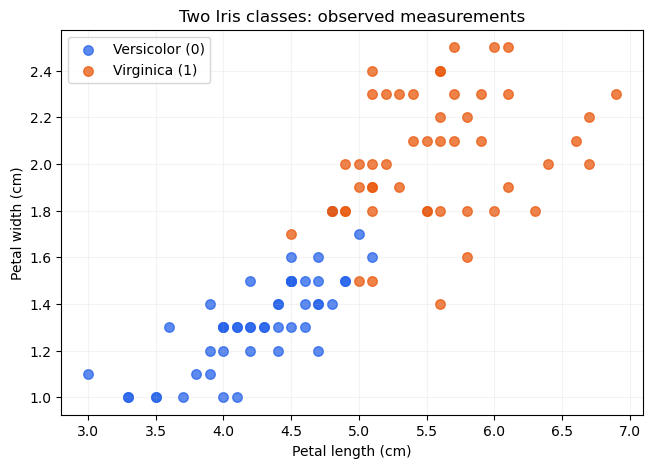

In [ ]:
fig, ax = plt.subplots(figsize=(7.5, 5))
for class_value, label, color in [(0, "Versicolor (0)", "#2563eb"),
                                  (1, "Virginica (1)", "#ea580c")]:
    group = X[y == class_value]
    ax.scatter(group.iloc[:, 0], group.iloc[:, 1],
               s=47, alpha=0.75, color=color, label=label)
ax.set(xlabel="Petal length (cm)", ylabel="Petal width (cm)",
       title="Two Iris classes: observed measurements")
ax.legend()
ax.grid(alpha=0.15)
plt.show()

## 5. Split into training and test data

We train using **70%** of the records and evaluate on the remaining **30%**.

- `random_state=42` makes the split reproducible.
- `stratify=y` preserves the class proportions in both sets.
- We never learn model parameters from the test set.

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.30, random_state=42, stratify=y
)
print("X_train:", X_train.shape, "X_test:", X_test.shape)
print("y_train distribution:", y_train.value_counts().sort_index().to_dict())
print("y_test distribution:", y_test.value_counts().sort_index().to_dict())

X_train: (70, 2) X_test: (30, 2)
y_train distribution: {0: 35, 1: 35}
y_test distribution: {0: 15, 1: 15}


## 6. Standardize features and train Logistic Regression

We place `StandardScaler()` and `LogisticRegression()` in one **Pipeline**.

The scaler learns means and standard deviations **only from the training data** during `fit()`. The fitted scaler transforms the test data automatically during `predict()` or `predict_proba()`.

Standardization applies $x_{scaled}=(x-\mu_{train})/\sigma_{train}$; it is helpful for the optimization and regularization used by Logistic Regression.

`LogisticRegression()` **does not** run ordinary least-squares Linear Regression. It learns its own coefficients by optimizing the logistic classification objective.

In [ ]:
model = Pipeline(steps=[
    ("scaler", StandardScaler()),
    ("logistic", LogisticRegression(max_iter=1000, random_state=42))
])

model.fit(X_train, y_train)
print("Model fitted successfully.")
print("Class order:", model.named_steps["logistic"].classes_)

Model fitted successfully.
Class order: [0 1]


## 7. Understand the linear score: $z=b_0+b_1x_1+b_2x_2$

**This is the 'linear' part of Logistic Regression.**

Here `x1` and `x2` mean the **standardized** features, because the pipeline standardizes the inputs before the logistic estimator sees them.

- `coef_` contains $b_1$ and $b_2$.
- `intercept_` contains $b_0$.
- A positive coefficient raises the score $z$ as that standardized feature increases while the other is held fixed.
- These coefficients act on **log-odds**, not directly on probability.

In [ ]:
logistic = model.named_steps["logistic"]
b0 = logistic.intercept_[0]
b1, b2 = logistic.coef_[0]

print(f"Intercept b0 = {b0:.4f}")
print(f"b1 for {feature_names[0]} (standardized) = {b1:.4f}")
print(f"b2 for {feature_names[1]} (standardized) = {b2:.4f}")
print(f"\nLinear score: z = {b0:.4f} + ({b1:.4f} × x1_scaled) + ({b2:.4f} × x2_scaled)")

Intercept b0 = 0.1974
b1 for petal length (cm) (standardized) = 1.7118
b2 for petal width (cm) (standardized) = 2.2641

Linear score: z = 0.1974 + (1.7118 × x1_scaled) + (2.2641 × x2_scaled)


## 9. `predict()` vs `predict_proba()`

- `predict()` returns the final class label, **0 or 1**.
- `predict_proba()` returns two probabilities per record: `[P(class 0), P(class 1)]`.
- Here, column 1 of `predict_proba()` is specifically **P(virginica)** because classes are `[0,1]`.

Note: Class assignment uses a decision threshold; 0.5 is the usual default for this binary example.

In [ ]:
y_pred = model.predict(X_test)
y_prob = model.predict_proba(X_test)[:, 1]

comparison = pd.DataFrame({
    "Actual (0/1)": y_test.to_numpy(),
    "Predicted (0/1)": y_pred,
    "P(Virginica=1)": y_prob
})
display(comparison.head(10))

,Actual (0/1),Predicted (0/1),P(Virginica=1)
0,0,0,0.0253
1,0,0,0.0010
2,1,1,0.5169
3,0,0,0.0532
4,0,0,0.0124
5,1,1,0.8920
6,1,1,0.9969
7,1,1,0.9968
8,1,1,0.9070
9,0,1,0.5989


## 10. Evaluate the classification model

**Accuracy** is the fraction of test observations classified correctly.

**Precision (class 1)** asks: *Of the flowers predicted as virginica, how many actually were virginica?*

**Recall (class 1)** asks: *Of the actual virginica flowers, how many were found?*

**F1-score** balances precision and recall. **Log Loss** judges probability quality; **ROC AUC** summarizes ranking performance over thresholds.

We do **not** use R² or Adjusted R² for this classification task.

In [ ]:
print(f"Test accuracy: {accuracy_score(y_test, y_pred):.3f}")
print(f"Test precision (Virginica=1): {precision_score(y_test, y_pred):.3f}")
print(f"Test recall    (Virginica=1): {recall_score(y_test, y_pred):.3f}")
print(f"Test ROC AUC: {roc_auc_score(y_test, y_prob):.3f}")
print(f"Test Log Loss: {log_loss(y_test, y_prob):.3f}")
print("\nClassification report:")
print(classification_report(y_test, y_pred, target_names=["Versicolor", "Virginica"]))

Test accuracy: 0.900
Test precision (Virginica=1): 0.929
Test recall    (Virginica=1): 0.867
Test ROC AUC: 0.987
Test Log Loss: 0.217

Classification report:
              precision    recall  f1-score   support

  Versicolor       0.88      0.93      0.90        15
   Virginica       0.93      0.87      0.90        15

    accuracy                           0.90        30
   macro avg       0.90      0.90      0.90        30
weighted avg       0.90      0.90      0.90        30



## 11. Confusion matrix — where did the model succeed or fail?

For the class order `[0,1]`:

| | Predicted 0 | Predicted 1 |
|---|---|---|
| **Actual 0** | True Negative (TN) | False Positive (FP) |
| **Actual 1** | False Negative (FN) | True Positive (TP) |

Our *positive class* is **Virginica (1)**.

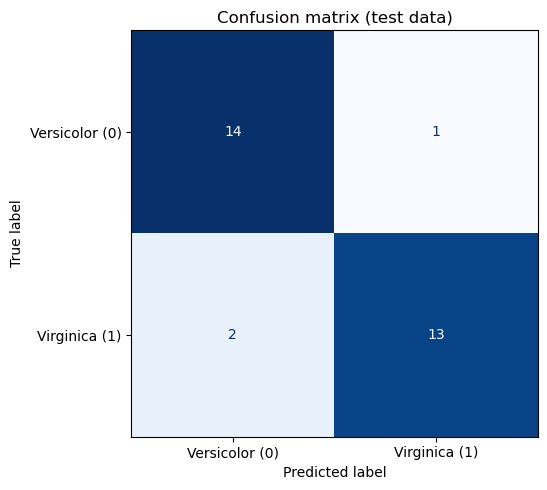

In [ ]:
fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred,
    display_labels=["Versicolor (0)", "Virginica (1)"],
    cmap="Blues", values_format="d", ax=ax,
    colorbar=False
)
ax.set_title("Confusion matrix (test data)")
plt.tight_layout()
plt.show()

In [ ]:
rows = []
for threshold in [0.30, 0.50, 0.70]:
    predictions_at_threshold = (y_prob >= threshold).astype(int)
    rows.append({
        "Threshold": threshold,
        "Accuracy": accuracy_score(y_test, predictions_at_threshold),
        "Precision (1)": precision_score(y_test, predictions_at_threshold, zero_division=0),
        "Recall (1)": recall_score(y_test, predictions_at_threshold, zero_division=0),
        "Predicted Virginica": int(predictions_at_threshold.sum())
    })
display(pd.DataFrame(rows).round(3))

,Threshold,Accuracy,Precision (1),Recall (1),Predicted Virginica
0,0.3,0.967,0.938,1.000,16
1,0.5,0.900,0.929,0.867,14
2,0.7,0.867,1.000,0.733,11


## 15. Predict a new flower

When we pass a **DataFrame with the same feature names** to the pipeline, it automatically applies the training-fitted scaler before predicting.

The values here are a teaching example, not a new observed flower.

In [ ]:
new_flower = pd.DataFrame({
    "petal length (cm)": [5.1],
    "petal width (cm)": [1.8]
})

new_probability = model.predict_proba(new_flower)[0, 1]
new_prediction = int(model.predict(new_flower)[0])
print("P(Virginica):", round(new_probability, 4))
print("Predicted class:", "Virginica (1)" if new_prediction else "Versicolor (0)")

P(Virginica): 0.7393
Predicted class: Virginica (1)
